# 3.2 Low CF Detection — Pulse Event Characteristics

This notebook produces a three-panel PNAS-ready figure (single column, 3.42 in wide).

**Workflow:** run cells 1–3 once to load data and set up style, then preview each panel individually (cells 4–6), and finally run cell 7 to assemble and save the combined figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.collections import PatchCollection
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
groups_df = pd.read_parquet(file, engine='pyarrow')


# prep data

In [3]:
#PNAS params
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    7,
    "axes.titlesize":    8,
    "xtick.labelsize":   6,
    "ytick.labelsize":   6,
    "legend.fontsize":   6,
    "lines.linewidth":   0.8,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
    "svg.fonttype":      "none",
    "savefig.dpi":       600})

#other params
pulse_color = "red" 
bg_color = "cornflowerblue"
start_color='orange'

size_bins = [1, 2, 4, 11, 31, 101]
size_labels  = ["1", "2-3", "4–10", "11–30", "31–100"]

size_colors = [
    "tab:blue",
    "tab:orange",
    "tab:purple",
    "tab:olive",
    "tab:red"
]
# size_colors = [
#     "rosybrown",
#     "darkseagreen",
#     "palegoldenrod",
#     "thistle",
#     "indianred"
# ]
#size_colors = ["aliceblue", "lightskyblue", "cornflowerblue", "royalblue","navy"]
#size_colors = ["lightcoral", "mediumaquamarine", "gold", "lavender", "red"]

In [4]:
#data prep 

#subsetting pulse starts 
pulse_df =df[df["pulse_start"] ==True].copy()
pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])
pulse_df["_hour"] = pulse_df["datetime_local"].dt.hour
pulse_df["_month"] = pulse_df["datetime_local"].dt.month

all_unique__cells = df[["grid_lat", "grid_lon"]].drop_duplicates()

#calculate group size which is the number of unqiue grid cells per group 
group_sizes = (groups_df.drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"]).groupby("group_id").size()
               .reset_index(name="group_size"))

#making a centroid for each pulse group 
group_centroids = (groups_df.drop_duplicates(subset=["group_id", "grid_lat", "grid_lon"])
                   .groupby("group_id")[["grid_lat", "grid_lon"]].mean().reset_index()
                   .rename(columns={"grid_lat": "centroid_lat", "grid_lon": "centroid_lon"})
                   .merge(group_sizes, on="group_id"))

#want one row per pulse-start event, with group size and size bin
groups_df_t = groups_df.copy()
groups_df_t["datetime_local"] =pd.to_datetime(groups_df_t["datetime_local"])
pulse_groups =groups_df_t[groups_df_t["pulse_start"] == True].copy()
pulse_groups["_hour"] =pulse_groups["datetime_local"].dt.hour
pulse_groups["_month"]= pulse_groups["datetime_local"].dt.month
pulse_groups= pulse_groups.merge(group_sizes, on="group_id")
pulse_groups["size_bin"] = pd.cut(pulse_groups["group_size"], bins=size_bins, labels=size_labels, right=False)

#NO2 arrays for KDE
bg_vals = df.loc[df["pulse_start"] != True,"no2_mean"].dropna().values
start_vals = pulse_df["no2_mean"].dropna().values

#KDE range for x 
lo =np.percentile(np.concatenate([bg_vals, start_vals]), 0.5)
hi =np.percentile(np.concatenate([bg_vals, start_vals]), 99.5)
kde_x = np.linspace(lo, hi, 400)
kde_bg= gaussian_kde(bg_vals, bw_method="scott")
kde_start = gaussian_kde(start_vals, bw_method="scott")

print("done")
print(f"pulse-start rows: {len(pulse_df):,}")
print(f"pulse groups: {len(group_centroids):,}")
print(f"median group size (cells):{group_sizes['group_size'].median():.0f}")
print(f"background NO2 obs: {len(bg_vals):,}")


done
pulse-start rows: 2,009
pulse groups: 777
median group size (cells):1
background NO2 obs: 2,587,507


# first panel is map 

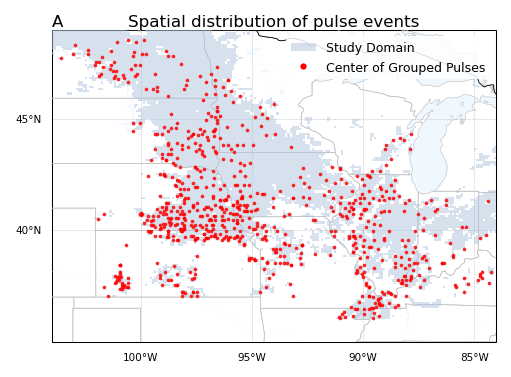

In [5]:
map_extent = [-104, -84, 35, 49]
domain_alpha = 0.5
centroid_size = 3
centroid_alpha = 0.85
gridline_x = range(-110, -75, 5)
gridline_y= range(35, 55, 5)
cell_w =0.1
cell_h =0.1

#figure setup
proj = ccrs.PlateCarree()
fig_a, ax_map = plt.subplots(figsize=(3.42, 2.6), dpi=150, subplot_kw={"projection": proj})
ax_map.set_extent(map_extent, crs=proj)

ax_map.add_feature(cfeature.LAND.with_scale("50m"),    facecolor="white",     zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),   facecolor="aliceblue", linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"),  edgecolor="aliceblue", linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),  edgecolor="silver",    linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black",     linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

#want rectnagles same size as grid cells 
rects = []
for lon, lat in zip(all_unique__cells["grid_lon"], all_unique__cells["grid_lat"]):
    rects.append(Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h))
pc = PatchCollection(rects, facecolor="lightsteelblue", edgecolor="none",
                     alpha=domain_alpha, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)

#scatter pulses as the center of each pulse 
ax_map.scatter(group_centroids["centroid_lon"], group_centroids["centroid_lat"], 
               s=centroid_size, c="red", alpha=centroid_alpha,
               linewidths=0, transform=proj, zorder=8)

# Gridlines
gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray",
                      alpha=0.5, linestyle="--",
                      xlocs=gridline_x, ylocs=gridline_y)
gl.top_labels= False
gl.right_labels =False
gl.xlabel_style ={"size": 5}
gl.ylabel_style ={"size": 5}

#lengend
legend_els = [Patch(facecolor="lightsteelblue", edgecolor="none", alpha=domain_alpha, label="Study Domain"),
              Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=4, label="Center of Grouped Pulses")]

ax_map.legend(handles=legend_els, loc="upper right",frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left",pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

plt.tight_layout()
plt.show()

# second figure is temporal graph of pulses

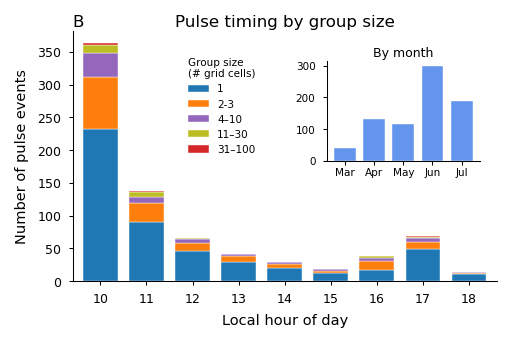

In [6]:
#params
hour_min= 10
hour_max= 18
bar_width = 0.75
months= [3, 4, 5, 6, 7]
month_labels = ["Mar", "Apr", "May", "Jun", "Jul"]

fig_b, ax_timing = plt.subplots(figsize=(3.42, 2.3), dpi=150)

#main panel is hourly timing with group size info 
pulse_groups_deduplicate = (pulse_groups.drop_duplicates(subset="group_id")) #want one row per group not indiv pulse 

#main figure
stacked = (pulse_groups_deduplicate.groupby(["_hour", "size_bin"], observed=True).size().unstack(fill_value=0)
           .reindex(columns=size_labels, fill_value=0))
stacked =stacked.reindex(range(hour_min, hour_max + 1),fill_value=0)

bottom = np.zeros(len(stacked))
for label, color in zip(size_labels, size_colors):
    vals = stacked[label].values
    ax_timing.bar(stacked.index, vals, bottom=bottom, width=bar_width, color=color, label=label, edgecolor="white", linewidth=0.2,)
    bottom += vals

ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(hour_min - 0.6, hour_max + 0.6)
ax_timing.set_xticks(range(hour_min, hour_max + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend(title="Group size\n(# grid cells)", title_fontsize=5, fontsize=5, loc="center left",
                 bbox_to_anchor=(0.25, 0.7),frameon=False)

ax_timing.set_title("B", loc="left",pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

#add inset of months bar graph 
monthly_counts = (pulse_groups_deduplicate.groupby("_month").size().reindex(months, fill_value=0))

ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
ax_month.bar(np.arange(len(months)), monthly_counts.values, color="cornflowerblue", edgecolor="white", linewidth=0.2, width=0.75)
ax_month.set_xticks(np.arange(len(months)))
ax_month.set_xticklabels(month_labels)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.tick_params(axis="x", labelsize=5, pad=1, length=2)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.spines[["top", "right"]].set_visible(False)
ax_month.set_ylabel("")
ax_month.set_xlabel("")

plt.tight_layout()
plt.show()

# third figure

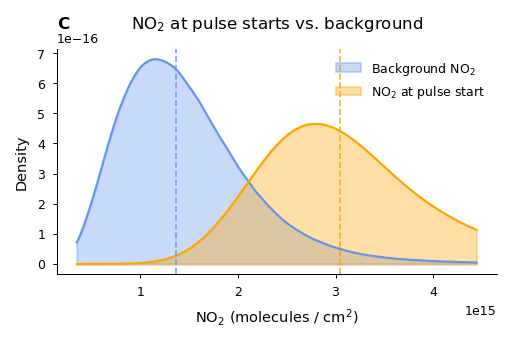

In [7]:
fig_c, ax_kde = plt.subplots(figsize=(3.42, 2.3), dpi=150)

ax_kde.fill_between(kde_x, kde_bg(kde_x),alpha=0.35, color=bg_color, label="Background NO$_2$")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=start_color, label="NO$_2$ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x), color=bg_color, linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=start_color, linewidth=1.0)

for vals, color in [(bg_vals, bg_color), (start_vals, start_color )]:
    ax_kde.axvline(np.median(vals), color=color, linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel(f"NO$_2$ (molecules / cm$^2$)")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C",loc="left", fontweight="bold", pad=2)
ax_kde.set_title("NO$_2$ at pulse starts vs. background", pad=2)

plt.tight_layout()
plt.show()

# one figure all together

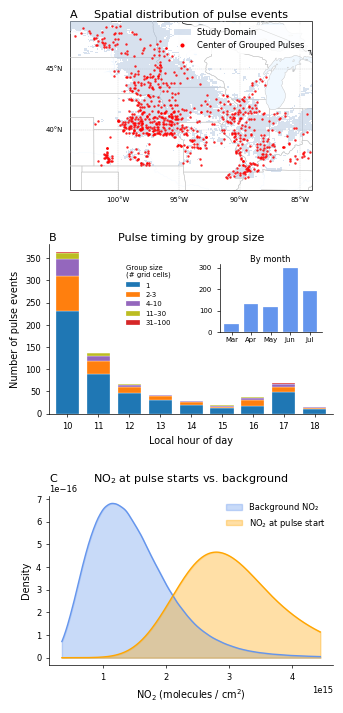

Saved: pulse_3panel_PNAS.pdf


In [8]:
#pnas settings
cm = 1 / 2.54
fig_width = 8.7 * cm
fig_height = 18  * cm

proj =ccrs.PlateCarree()
fig =plt.figure(figsize=(fig_width, fig_height))
gs = gridspec.GridSpec(3, 1, figure=fig, hspace=0.4, top=0.97, bottom=0.06, left=0.14, right=0.97)

#first panel 
ax_map = fig.add_subplot(gs[0], projection=proj)
ax_map.set_extent(map_extent, crs=proj)
ax_map.add_feature(cfeature.LAND.with_scale("50m"),facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"), facecolor="aliceblue",linewidth=0.2, zorder=2)
ax_map.add_feature(cfeature.RIVERS.with_scale("50m"), edgecolor="aliceblue",linewidth=0.2, zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"),edgecolor="silver", linewidth=0.3, zorder=4)
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),edgecolor="black",linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m", linewidth=0.4, zorder=6)

rects = []
for lon, lat in zip(all_unique__cells["grid_lon"], all_unique__cells["grid_lat"]):
    rects.append(Rectangle((lon - cell_w/2, lat - cell_h/2), cell_w, cell_h))
pc = PatchCollection(rects, facecolor="lightsteelblue", edgecolor="none", 
                     alpha=domain_alpha, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)
ax_map.scatter( group_centroids["centroid_lon"], group_centroids["centroid_lat"], 
               s=centroid_size, c="red", alpha=centroid_alpha,
               linewidths=0, transform=proj, zorder=8 )

gl = ax_map.gridlines(draw_labels=True, linewidth=0.25, color="gray",
                      alpha=0.5, linestyle="--",
                      xlocs=gridline_x, ylocs=gridline_y)
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {"size": 5}; gl.ylabel_style = {"size": 5}
legend_els = [
    Patch(facecolor="lightsteelblue", edgecolor="none", alpha=domain_alpha, label="Study Domain"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="red", markersize=4, label="Center of Grouped Pulses"),
]
ax_map.legend(handles=legend_els, loc="upper right",
              frameon=True, framealpha=0.85, edgecolor="none", fontsize=6)
ax_map.set_title("A", loc="left", pad=2)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

#second panel 
ax_timing = fig.add_subplot(gs[1])

pulse_groups_deduplicate = pulse_groups.drop_duplicates(subset="group_id")

stacked = (pulse_groups_deduplicate.groupby(["_hour", "size_bin"], observed=True)
           .size().unstack(fill_value=0).reindex(columns=size_labels, fill_value=0))
stacked = stacked.reindex(range(hour_min, hour_max + 1), fill_value=0)

bottom = np.zeros(len(stacked))
for label, color in zip(size_labels, size_colors):
    vals = stacked[label].values
    ax_timing.bar(stacked.index, vals, bottom=bottom, width=bar_width,
                  color=color, label=label, edgecolor="white", linewidth=0.2)
    bottom += vals

ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(hour_min - 0.6, hour_max + 0.6)
ax_timing.set_xticks(range(hour_min, hour_max + 1))
ax_timing.spines[["top", "right"]].set_visible(False)
ax_timing.legend( title="Group size\n(# grid cells)", title_fontsize=5, fontsize=5, loc="center left",
                 bbox_to_anchor=(0.25, 0.7), frameon=False)
ax_timing.set_title("B", loc="left", pad=2)
ax_timing.set_title("Pulse timing by group size", pad=2)

monthly_counts = (pulse_groups_deduplicate.groupby("_month").size().reindex(months, fill_value=0))
ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
ax_month.bar(np.arange(len(months)), monthly_counts.values,
    color="cornflowerblue", edgecolor="white", linewidth=0.2, width=0.75)
ax_month.set_xticks(np.arange(len(months)))
ax_month.set_xticklabels(month_labels)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.tick_params(axis="x",labelsize=5, pad=1, length=2)
ax_month.tick_params(axis="y", labelsize=5, length=2)
ax_month.spines[["top", "right"]].set_visible(False)
ax_month.set_ylabel("")
ax_month.set_xlabel("")

#last panel 
ax_kde = fig.add_subplot(gs[2])
ax_kde.fill_between(kde_x, kde_bg(kde_x), alpha=0.35, color=bg_color, label="Background NO₂")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=start_color, label="NO$_2$ at pulse start")
ax_kde.plot(kde_x, kde_bg(kde_x), color=bg_color, linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=start_color, linewidth=1.0)
# for vals, color in [(bg_vals, bg_color), (start_vals, start_color)]:
#     ax_kde.axvline(np.median(vals), color=color, linewidth=0.8, linestyle="--", alpha=0.85)
ax_kde.set_xlabel(f"NO$_2$ (molecules / cm$^2$)")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("C", loc="left", pad=2)
ax_kde.set_title("NO$_2$ at pulse starts vs. background", pad=2)

# Fine-tune vertical positions manually
# Format: [left, bottom, width, height] in figure fraction
pos_a = ax_map.get_position()
pos_b = ax_timing.get_position()

# Move panel B up slightly (increase its bottom) to close the A→B gap
#ax_map.set_position([pos_a, pos_a, pos_a.width *0.6, pos_a.height])
ax_timing.set_position([pos_b.x0, pos_b.y0 + 0.02, pos_b.width, pos_b.height])
ax_month.set_position([
    pos_b.x0 + pos_b.width * 0.60,
    pos_b.y0 + 0.04 + pos_b.height * 0.48,
    pos_b.width * 0.36,
    pos_b.height * 0.40,
])


#save
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/pulse_3panel_PNAS.pdf", bbox_inches="tight")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf") 

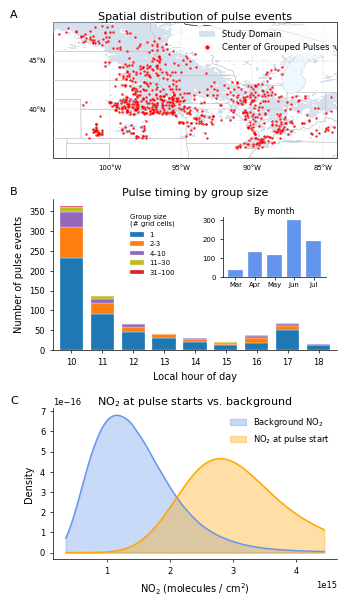

Saved: pulse_3panel_PNAS.pdf


In [9]:
#pnas settings
cm = 1 / 2.54
fig_width = 8.7 * cm
fig_height = 15  * cm

proj = ccrs.PlateCarree()
fig = plt.figure(figsize=(fig_width, fig_height))

gs = gridspec.GridSpec(3, 1, figure=fig, hspace=0.34, top=0.97, bottom=0.06, left=0.14, right=0.97, height_ratios=[0.90, 1, 1])

# first panel 
ax_map = fig.add_subplot(gs[0], projection=proj)

ax_map.set_extent(map_extent, crs=proj)

ax_map.add_feature(cfeature.LAND.with_scale("50m"),facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),facecolor="aliceblue",linewidth=0.2,zorder=2)
ax_map.add_feature( cfeature.RIVERS.with_scale("50m"),edgecolor="aliceblue",linewidth=0.2,zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.3,  zorder=4)
ax_map.add_feature( cfeature.BORDERS.with_scale("50m"), edgecolor="black",linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m",linewidth=0.4, zorder=6)

rects = []

for lon, lat in zip(all_unique__cells["grid_lon"], all_unique__cells["grid_lat"]):
    rects.append(Rectangle((lon - cell_w / 2, lat - cell_h / 2), cell_w, cell_h))

pc = PatchCollection(rects,facecolor="lightsteelblue",edgecolor="none",alpha=domain_alpha, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)
ax_map.scatter(group_centroids["centroid_lon"], group_centroids["centroid_lat"], s=centroid_size, c="red",
               alpha=centroid_alpha, linewidths=0, transform=proj,zorder=80)

gl = ax_map.gridlines(draw_labels=True,linewidth=0.25, color="gray", alpha=0.5, linestyle="--", xlocs=gridline_x, ylocs=gridline_y)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 5}
gl.ylabel_style = {"size": 5}

legend_els = [Patch( facecolor="lightsteelblue", edgecolor="none", alpha=domain_alpha,label="Study Domain"),
              Line2D([0], [0],marker="o", color="w", markerfacecolor="red", markersize=4, label="Center of Grouped Pulses")]

ax_map.legend(handles=legend_els,loc="upper right",frameon=True, framealpha=0.85,edgecolor="none",fontsize=6)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# second panel 
ax_timing = fig.add_subplot(gs[1])
pulse_groups_deduplicate = pulse_groups.drop_duplicates(subset="group_id")
stacked = (pulse_groups_deduplicate.groupby(["_hour", "size_bin"], observed=True).size().unstack(fill_value=0)
           .reindex(columns=size_labels, fill_value=0))

stacked = stacked.reindex(range(hour_min, hour_max + 1), fill_value=0)
bottom = np.zeros(len(stacked))
for label, color in zip(size_labels, size_colors):
    vals = stacked[label].values

    ax_timing.bar(stacked.index,vals,bottom=bottom,  width=bar_width, color=color, label=label, edgecolor="white",  linewidth=0.2)
    bottom += vals
    
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(hour_min - 0.6, hour_max + 0.6)
ax_timing.set_xticks(range(hour_min, hour_max + 1))
ax_timing.spines[["top", "right"]].set_visible(False)

ax_timing.legend( title="Group size\n(# grid cells)",title_fontsize=5, fontsize=5,loc="center left", bbox_to_anchor=(0.25, 0.70), frameon=False)
ax_timing.set_title("Pulse timing by group size", pad=2)

# monthly inset 
monthly_counts = (pulse_groups_deduplicate.groupby("_month").size().reindex(months, fill_value=0))
ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
ax_month.bar(np.arange(len(months)),monthly_counts.values, color="cornflowerblue",  edgecolor="white", linewidth=0.2, width=0.75)

ax_month.set_xticks(np.arange(len(months)))
ax_month.set_xticklabels(month_labels)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.tick_params(axis="x",labelsize=5, pad=1,length=2)
ax_month.tick_params(axis="y",labelsize=5, length=2)
ax_month.spines[["top", "right"]].set_visible(False)
ax_month.set_ylabel("")
ax_month.set_xlabel("")


# last panel 
ax_kde = fig.add_subplot(gs[2])

ax_kde.fill_between(kde_x, kde_bg(kde_x), alpha=0.35, color=bg_color, label="Background NO$_2$")
ax_kde.fill_between(kde_x, kde_start(kde_x), alpha=0.35, color=start_color, label="NO$_2$ at pulse start")

ax_kde.plot(kde_x, kde_bg(kde_x), color=bg_color, linewidth=1.0)
ax_kde.plot(kde_x, kde_start(kde_x), color=start_color, linewidth=1.0)

# for vals, color in [(bg_vals, bg_color), (start_vals, start_color)]:
#     ax_kde.axvline(np.median(vals), color=color, linewidth=0.8, linestyle="--", alpha=0.85)

ax_kde.set_xlabel("NO$_2$ (molecules / cm$^2$)")
ax_kde.set_ylabel("Density")
ax_kde.spines[["top", "right"]].set_visible(False)
ax_kde.legend(loc="upper right", frameon=False)
ax_kde.set_title("NO$_2$ at pulse starts vs. background", pad=2)


# align panels
fig.canvas.draw()

pos_a = ax_map.get_position()
pos_b = ax_timing.get_position()
pos_c = ax_kde.get_position()

left = pos_b.x0
right = pos_b.x1
width = right - left

# this lets Cartopy use the full axis width
ax_map.set_aspect("auto")

ax_map.set_position([left, pos_a.y0, width, pos_a.height])
ax_timing.set_position([left, pos_b.y0 +0.015, width, pos_b.height])
ax_kde.set_position([left, pos_c.y0, width, pos_c.height])


# 
# reposition monthly inset after aligning panel B
fig.canvas.draw()

pos_b = ax_timing.get_position()
ax_month.set_position([pos_b.x0 + pos_b.width * 0.60, pos_b.y0 + pos_b.height * 0.4, pos_b.width * 0.36, pos_b.height * 0.40])


# add aligned panel labels
fig.canvas.draw()

label_x = left - 0.035
label_pad = 0.004

for ax, label in zip([ax_map, ax_timing, ax_kde], ["A", "B", "C"]):
    pos = ax.get_position()
    fig.text(label_x - 0.09, pos.y1 + label_pad, label, ha="left", va="bottom", fontsize=8)


#save
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/pulse_3panel_PNAS.pdf")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf")

# without third panel 

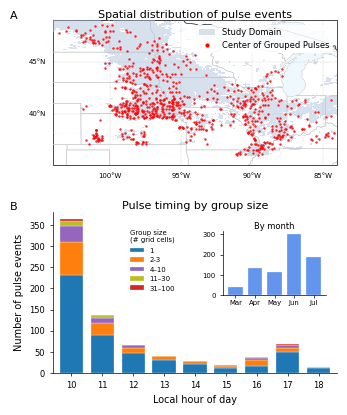

Saved: pulse_3panel_PNAS.pdf


In [13]:
#pnas settings
cm = 1 / 2.54
fig_width = 8.7 * cm
fig_height = 10  * cm

proj = ccrs.PlateCarree()
fig = plt.figure(figsize=(fig_width, fig_height))

gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0.34, top=0.97, bottom=0.06, left=0.14, right=0.97, height_ratios=[0.90, 1])

# first panel 
ax_map = fig.add_subplot(gs[0], projection=proj)

ax_map.set_extent(map_extent, crs=proj)

ax_map.add_feature(cfeature.LAND.with_scale("50m"),facecolor="white", zorder=1)
ax_map.add_feature(cfeature.LAKES.with_scale("50m"),facecolor="aliceblue",linewidth=0.2,zorder=2)
ax_map.add_feature( cfeature.RIVERS.with_scale("50m"),edgecolor="aliceblue",linewidth=0.2,zorder=3)
ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.3,  zorder=4)
ax_map.add_feature( cfeature.BORDERS.with_scale("50m"), edgecolor="black",linewidth=0.4, zorder=5)
ax_map.coastlines(resolution="50m",linewidth=0.4, zorder=6)

rects = []

for lon, lat in zip(all_unique__cells["grid_lon"], all_unique__cells["grid_lat"]):
    rects.append(Rectangle((lon - cell_w / 2, lat - cell_h / 2), cell_w, cell_h))

pc = PatchCollection(rects,facecolor="lightsteelblue",edgecolor="none",alpha=domain_alpha, linewidth=0, zorder=7)
pc.set_transform(proj)
ax_map.add_collection(pc)
ax_map.scatter(group_centroids["centroid_lon"], group_centroids["centroid_lat"], s=centroid_size, c="red",
               alpha=centroid_alpha, linewidths=0, transform=proj,zorder=80)

gl = ax_map.gridlines(draw_labels=True,linewidth=0.25, color="gray", alpha=0.5, linestyle="--", xlocs=gridline_x, ylocs=gridline_y)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 5}
gl.ylabel_style = {"size": 5}

legend_els = [Patch( facecolor="lightsteelblue", edgecolor="none", alpha=domain_alpha,label="Study Domain"),
              Line2D([0], [0],marker="o", color="w", markerfacecolor="red", markersize=4, label="Center of Grouped Pulses")]

ax_map.legend(handles=legend_els,loc="upper right",frameon=True, framealpha=0.85,edgecolor="none",fontsize=6)
ax_map.set_title("Spatial distribution of pulse events", pad=2)

# second panel 
ax_timing = fig.add_subplot(gs[1])
pulse_groups_deduplicate = pulse_groups.drop_duplicates(subset="group_id")
stacked = (pulse_groups_deduplicate.groupby(["_hour", "size_bin"], observed=True).size().unstack(fill_value=0)
           .reindex(columns=size_labels, fill_value=0))

stacked = stacked.reindex(range(hour_min, hour_max + 1), fill_value=0)
bottom = np.zeros(len(stacked))
for label, color in zip(size_labels, size_colors):
    vals = stacked[label].values

    ax_timing.bar(stacked.index,vals,bottom=bottom,  width=bar_width, color=color, label=label, edgecolor="white",  linewidth=0.2)
    bottom += vals
    
ax_timing.set_xlabel("Local hour of day")
ax_timing.set_ylabel("Number of pulse events")
ax_timing.set_xlim(hour_min - 0.6, hour_max + 0.6)
ax_timing.set_xticks(range(hour_min, hour_max + 1))
ax_timing.spines[["top", "right"]].set_visible(False)

ax_timing.legend( title="Group size\n(# grid cells)",title_fontsize=5, fontsize=5,loc="center left", bbox_to_anchor=(0.25, 0.70), frameon=False)
ax_timing.set_title("Pulse timing by group size", pad=2)

# monthly inset 
monthly_counts = (pulse_groups_deduplicate.groupby("_month").size().reindex(months, fill_value=0))
ax_month = ax_timing.inset_axes([0.60, 0.48, 0.36, 0.40])
ax_month.bar(np.arange(len(months)),monthly_counts.values, color="cornflowerblue",  edgecolor="white", linewidth=0.2, width=0.75)

ax_month.set_xticks(np.arange(len(months)))
ax_month.set_xticklabels(month_labels)
ax_month.set_title("By month", fontsize=6, pad=2)
ax_month.tick_params(axis="x",labelsize=5, pad=1,length=2)
ax_month.tick_params(axis="y",labelsize=5, length=2)
ax_month.spines[["top", "right"]].set_visible(False)
ax_month.set_ylabel("")
ax_month.set_xlabel("")

# align panels
fig.canvas.draw()

pos_a = ax_map.get_position()
pos_b = ax_timing.get_position()

left = pos_b.x0
right = pos_b.x1
width = right - left

# this lets Cartopy use the full axis width
ax_map.set_aspect("auto")

ax_map.set_position([left, pos_a.y0, width, pos_a.height])
ax_timing.set_position([left, pos_b.y0 +0.015, width, pos_b.height])
 
# reposition monthly inset after aligning panel B
fig.canvas.draw()

pos_b = ax_timing.get_position()
ax_month.set_position([pos_b.x0 + pos_b.width * 0.60, pos_b.y0 + pos_b.height * 0.4, pos_b.width * 0.36, pos_b.height * 0.40])


# add aligned panel labels
fig.canvas.draw()

label_x = left - 0.035

for ax, label in zip([ax_map, ax_timing], ["A", "B"]):
    pos = ax.get_position()
    fig.text(label_x - 0.09, pos.y1, label, ha="left", va="bottom", fontsize=8)


#save
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/char_pulse_2panel_PNAS.pdf")
plt.show()
print("Saved: pulse_3panel_PNAS.pdf")

In [23]:
print(group_sizes["group_size"].value_counts().sort_index().head(10))
print(f"\nGroups with size 1: {(group_sizes['group_size'] == 1).sum()} out of {len(group_sizes)}")

group_size
1     507
2     123
3      44
4      30
5      11
6      12
7       9
8       4
9       4
10      2
Name: count, dtype: int64

Groups with size 1: 507 out of 777
